# Gradient descent

dj_dw: tells us how the cost changes with the weight.



dj_db: tells us how the cost changes with the bias.

In [1]:
import numpy as np

def compute_prediction(x, w, b):
    return w*x+b
    
    
import numpy as np
def compute_cost(x, y, w, b):
    y_predicted=compute_prediction(x,w,b)
    error=y_predicted-y 
    return (np.sum(error**2))/(2*len(y_predicted))


x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 4.0, 6.0])

w=0
b=0
def gradient_desc(x,y,w,b):
    y_predict=compute_prediction(x,w,b)
    error=y_predict-y 
    dj_w= (np.sum(x*error))/len(y_predict)
    dj_b=(np.sum(error))/len(y_predict)
    return (dj_w,dj_b)

print(gradient_desc(x,y,0,0))

(np.float64(-9.333333333333334), np.float64(-4.0))


# parameter update

In [2]:
import numpy as np

x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 4.0, 6.0])

w=0
b=0
alpha=0.1


In [3]:
def update_parameters(w, b, dj_dw, dj_db, alpha):
    w_new=w-alpha*dj_dw
    b_new=b-alpha*dj_db

    return (w_new,b_new)

print(update_parameters(0, 0, -9.3333, -4, 0.1))

(0.93333, 0.4)


In [4]:
w, b = update_parameters(0, 0, -9.3333333333, -4, 0.1)

y_predicted = compute_prediction(x, w, b)
new_cost = compute_cost(x, y, w, b)

print("Updated parameters:", w, b)
print("Predictions:", y_predicted)
print("New cost:", new_cost)

Updated parameters: 0.9333333333300001 0.4
Predictions: [1.33333333 2.26666667 3.2       ]
New cost: 1.8814814814954068


In [5]:
def gradient_descent(x,y,w_in,b_in,alpha,num_iters):
    w=w_in
    b=b_in
    cost_history=[]
    for i in range(num_iters):
        # cal gradient 
        y_predict=compute_prediction(x,w,b)
        error=y_predict-y 
        dj_w= (np.sum(x*error))/len(y_predict)
        dj_b=(np.sum(error))/len(y_predict)

        # update para
        w_new= w - alpha*dj_w
        b_new= b - alpha*dj_b
        w=w_new
        b=b_new
        value=compute_cost(x,y,w,b)
        #cost
        
        cost_history.append((w,b,value))
    return w,b,cost_history

x = np.array([1.0, 2.0, 3.0])
y = np.array([2.0, 4.0, 6.0])

w, b, cost_history = gradient_descent(
    x, y,
    w_in=0,
    b_in=0,
    alpha=0.1,
    num_iters=100
)

print("Final weight:", w)
print("Final bias:", b)
print("Initial cost:", cost_history[0][2])
print("Final cost:", cost_history[-1][2])


Final weight: 1.903229192261931
Final bias: 0.2199827919355365
Initial cost: 1.881481481481481
Final cost: 0.0034710976497046232


In [6]:
import numpy as np

x = np.array([1.0, 2.0, 3.0])
y = np.array([3.0, 5.0, 7.0])

def predict(x,w,b): # to predict y value 
    return w*x+b 

def cost_cal(x,w,b,y):
    y_predicted=predict(x,w,b)
    error= y_predicted-y 
    mean_square_error= (np.sum(error**2))/(2*len(y_predicted))
    return mean_square_error

def grad(x,w_in,b_in,y,alpha,iterations):
    w=w_in
    b=b_in
    cost_history=[]
    for i in range(iterations):
        y_predicted=predict(x,w,b)
        error=y_predicted-y
        dj_w= (np.sum(x*error))/len(y_predicted)
        dj_b=(np.sum(error))/len(y_predicted)

        w_new=w-alpha*dj_w
        w=w_new
        b_new=b-alpha*dj_b
        b=b_new

        cost= cost_cal(x,w,b,y)

        cost_history.append((w,b,cost))
    return (w,b,cost_history)


w, b, cost_history = grad(
    x, w_in=0, b_in=0, y=y,
    alpha=0.1, iterations=100
)

print("Final weight:", w)
print("Final bias:", b)
print("Initial cost:", cost_cal(x, 0, 0, y))
print("First updated cost:", cost_history[0][2])
print("Final cost:", cost_history[-1][2])

Final weight: 2.0132205882296996
Final bias: 0.9699464954589267
Initial cost: 13.833333333333334
First updated cost: 2.7442592592592585
Final cost: 6.478577479791293e-05


### Convergence and Learning Rates

In [7]:
w, b, cost_history = gradient_descent(
    x, y,
    w_in=0,
    b_in=0,
    alpha=0.1,
    num_iters=100
)

print("Initial cost:", compute_cost(x, y, 0, 0))
print("First updated cost:", cost_history[0][2])
print("Final cost:", cost_history[-1][2])

Initial cost: 13.833333333333334
First updated cost: 2.7442592592592585
Final cost: 6.478577479791293e-05


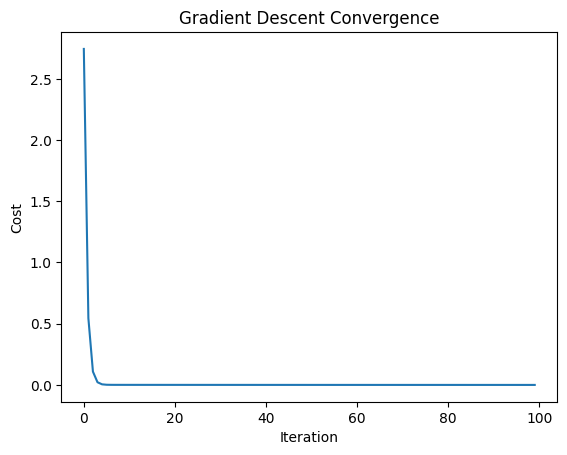

In [8]:
import matplotlib.pyplot as plt

costs = [entry[2] for entry in cost_history]

plt.plot(costs)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence")
plt.show()

In [10]:
def gradient_desc(x,w_in,b_in,y,alpha,iterations):
    w=w_in
    b=b_in
    cost_history=[]
    for i in range(iterations):
        y_predicted= predict(x,w,b)
        error= y_predicted-y 
        dj_w= (np.sum(x*error))/len(y_predicted)
        dj_b= (np.sum(error))/len(y_predicted)

        w_new= w - alpha*dj_w
        w=w_new
        b_new= b - alpha * dj_b 
        b=b_new

        cost= cost_cal(x,w,b,y)
        cost_history.append((w,b,cost))
    return (w,b,cost_history)



learning_rates=[0.001,0.01,0.1]
for alpha in learning_rates:
        w,b,cost_history=gradient_desc(x,0,0,y,alpha,1000)
        print("Learning rate:", alpha)
        print("Final weight:", w)
        print("Final bias:", b)
        print("Final cost:", cost_history[-1][2])


Learning rate: 0.001
Final weight: 2.031431020024596
Final bias: 0.9072434906159759
Final cost: 0.0007761426550011175
Learning rate: 0.01
Final weight: 2.0133075881026197
Final bias: 0.9697487242984874
Final cost: 6.564124347639164e-05
Learning rate: 0.1
Final weight: 2.0000002481557733
Final bias: 0.9999994358835982
Final cost: 2.2825845119815838e-14


### Gradient checking using numerical approximation

In [11]:
epsilon = 1e-5

numerical_dw = (
    cost_cal(x, w + epsilon, b, y)
    - cost_cal(x, w - epsilon, b, y)
) / (2 * epsilon)

numerical_db = (
    cost_cal(x, w, b + epsilon, y)
    - cost_cal(x, w, b - epsilon, y)
) / (2 * epsilon)

print("Numerical dw:", numerical_dw)
print("Numerical db:", numerical_db)

Numerical dw: 2.9827471902665735e-08
Numerical db: -6.780485543214862e-08


In [12]:
import numpy as np

x = np.array([1.0, 2.0, 3.0])
y = np.array([3.0, 5.0, 7.0])

w = 1.5
b = 0.5
epsilon = 1e-5


# 1. Prediction function
def predict(x, w, b):
    return w * x + b


# 2. Cost function
def cost_cal(x, w, b, y):
    y_predicted = predict(x, w, b)
    error = y_predicted - y
    return np.sum(error**2) / (2 * len(y))


# 3. Analytical gradients
def compute_gradient(x, y, w, b):
    y_predicted = predict(x, w, b)
    error = y_predicted - y

    dj_w = np.sum(x * error) / len(y)
    dj_b = np.sum(error) / len(y)

    return dj_w, dj_b


# 4. Analytical gradients
analytical_dw, analytical_db = compute_gradient(x, y, w, b)


# 5. Numerical gradients
numerical_dw = (
    cost_cal(x, w + epsilon, b, y)
    - cost_cal(x, w - epsilon, b, y)
) / (2 * epsilon)

numerical_db = (
    cost_cal(x, w, b + epsilon, y)
    - cost_cal(x, w, b - epsilon, y)
) / (2 * epsilon)


# 6. Compare gradients
print("Analytical dw:", analytical_dw)
print("Numerical dw:", numerical_dw)

print("Analytical db:", analytical_db)
print("Numerical db:", numerical_db)


# 7. Validate
dw_match = np.isclose(
    analytical_dw, numerical_dw, atol=1e-4
)

db_match = np.isclose(
    analytical_db, numerical_db, atol=1e-4
)

print("\nWeight gradient matches:", dw_match)
print("Bias gradient matches:", db_match)

if dw_match and db_match:
    print("Gradient checking PASSED")
else:
    print("Gradient checking FAILED")

Analytical dw: -3.3333333333333335
Numerical dw: -3.333333333388477
Analytical db: -1.5
Numerical db: -1.49999999997652

Weight gradient matches: True
Bias gradient matches: True
Gradient checking PASSED



--- Model Results ---
Final weight: 3.0080089257550604
Final bias: 0.9710852368058508
Initial cost: 59.0
Final cost: 7.608909497096617e-05

Actual values: [ 4.  7. 10. 13. 16.]
Predicted values: [ 3.97909416  6.98710309  9.99511201 13.00312094 16.01112987]

--- Validation ---
Weight close to 3: True
Bias close to 1: False
Cost decreased: True

--- Gradient Checking ---
Analytical dw: -36.0
Numerical dw: -36.00000000041348
Analytical db: -10.0
Numerical db: -9.999999999621423
Weight gradient matches: True
Bias gradient matches: True


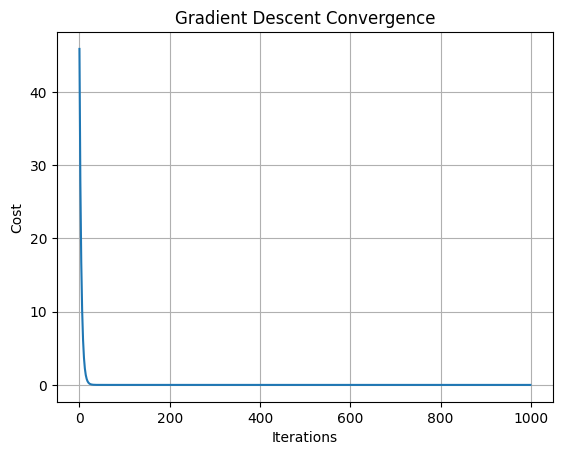

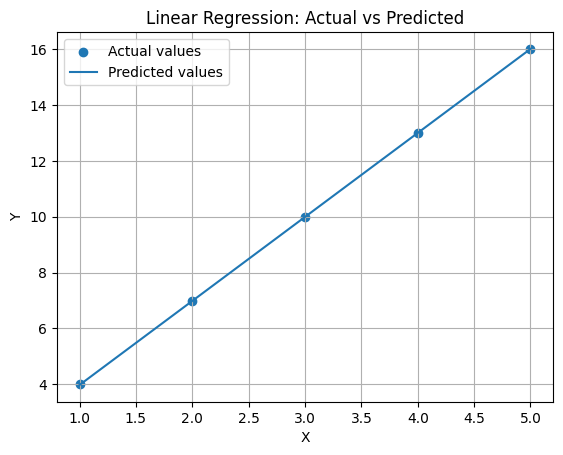

In [13]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. DATASET
# ==========================================

x = np.array([1.0, 2.0, 3.0, 4.0, 5.0])
y = np.array([4.0, 7.0, 10.0, 13.0, 16.0])


# ==========================================
# 2. PREDICTION FUNCTION
# ==========================================

def predict(x, w, b):
    return w * x + b


# ==========================================
# 3. COST FUNCTION
# ==========================================

def compute_cost(x, y, w, b):
    y_predicted = predict(x, w, b)
    error = y_predicted - y

    cost = np.sum(error ** 2) / (2 * len(y))

    return cost


# ==========================================
# 4. GRADIENT CALCULATION
# ==========================================

def compute_gradient(x, y, w, b):
    y_predicted = predict(x, w, b)
    error = y_predicted - y

    dj_dw = np.sum(x * error) / len(y)
    dj_db = np.sum(error) / len(y)

    return dj_dw, dj_db


# ==========================================
# 5. GRADIENT DESCENT TRAINING
# ==========================================

def gradient_descent(x, y, w_in, b_in, alpha, iterations):

    w = w_in
    b = b_in

    cost_history = []

    for i in range(iterations):

        # Calculate gradients
        dj_dw, dj_db = compute_gradient(x, y, w, b)

        # Update parameters
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        # Calculate cost after update
        cost = compute_cost(x, y, w, b)

        # Store training history
        cost_history.append((w, b, cost))

    return w, b, cost_history


# ==========================================
# 6. GRADIENT CHECKING
# ==========================================

def gradient_check(x, y, w, b, epsilon=1e-5):

    # Analytical gradients
    analytical_dw, analytical_db = compute_gradient(x, y, w, b)

    # Numerical weight gradient
    numerical_dw = (
        compute_cost(x, y, w + epsilon, b)
        - compute_cost(x, y, w - epsilon, b)
    ) / (2 * epsilon)

    # Numerical bias gradient
    numerical_db = (
        compute_cost(x, y, w, b + epsilon)
        - compute_cost(x, y, w, b - epsilon)
    ) / (2 * epsilon)

    # Compare gradients
    dw_match = np.isclose(
        analytical_dw, numerical_dw, atol=1e-4
    )

    db_match = np.isclose(
        analytical_db, numerical_db, atol=1e-4
    )

    print("\n--- Gradient Checking ---")

    print("Analytical dw:", analytical_dw)
    print("Numerical dw:", numerical_dw)

    print("Analytical db:", analytical_db)
    print("Numerical db:", numerical_db)

    print("Weight gradient matches:", dw_match)
    print("Bias gradient matches:", db_match)

    return dw_match and db_match


# ==========================================
# 7. TRAINING CONFIGURATION
# ==========================================

w_in = 0
b_in = 0

alpha = 0.01
iterations = 1000


# ==========================================
# 8. INITIAL COST
# ==========================================

initial_cost = compute_cost(x, y, w_in, b_in)


# ==========================================
# 9. TRAIN MODEL
# ==========================================

w, b, cost_history = gradient_descent(
    x, y,
    w_in,
    b_in,
    alpha,
    iterations
)


# ==========================================
# 10. MODEL EVALUATION
# ==========================================

y_predicted = predict(x, w, b)

final_cost = compute_cost(x, y, w, b)

print("\n--- Model Results ---")

print("Final weight:", w)
print("Final bias:", b)

print("Initial cost:", initial_cost)
print("Final cost:", final_cost)

print("\nActual values:", y)
print("Predicted values:", y_predicted)

print("\n--- Validation ---")

print("Weight close to 3:", np.isclose(w, 3, atol=0.01))
print("Bias close to 1:", np.isclose(b, 1, atol=0.01))
print("Cost decreased:", final_cost < initial_cost)

# ==========================================
# 11. GRADIENT CHECKING
# ==========================================

gradient_check(x, y, w_in, b_in)


# ==========================================
# 12. COST HISTORY VISUALIZATION
# ==========================================

costs = [entry[2] for entry in cost_history]

plt.plot(costs)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Gradient Descent Convergence")
plt.grid(True)
plt.show()


# ==========================================
# 13. ACTUAL VS PREDICTED VISUALIZATION
# ==========================================

plt.scatter(x, y, label="Actual values")
plt.plot(x, y_predicted, label="Predicted values")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()
